### Data Collection and Problem Formulation

#### FMCG Multi-country Sales Dataset
- This Dataset contains more than 1,100,000 rows of highly realistic FMCG sales data generated for professional demand planning, forecasting, and supply-chain analytics. It simulates a multi-country FMCG environment with:
   - a) 350+ SKUs (An SKU is : 3kg of salt is sold at 300 shillings- now that '30kg' is called an SKU)
   - b) 3 full years of daily sales
   - c) 15 countries, 60_ cities (with real lat/lon coordinates)
   - d) Multiple sales channels (Modern Trade, Traditional Trade, Wholesale, E-commerce)
   - e) Promotional effects  price elasticity
   - f) Seasonality patterns (weekly, monthly, yearly)
   - g) ABC/XYZ segmentation
   - h) Lead time variability
   - i) Stockouts & safety stock paramenters
- The key challanges that a multinational FMCG company faces across multiple regions:
   - a) High demand volatility
   - b) Frequent pro,otions impacting baselines
   - c) Low forecast accuracy
   - d) Nin-optimized safety stock levels
   - e) Stockouts on A-products and overstocks on C-products
   - f) Large discrepancies in country-level perfomance
   - g) Lack of integrated S&OP visibility

#### Core Objectives
1. Understand market dynamics and identify demand drivers
 - Total sales by country
 - Top 20 SKUs by revenue
 - Compare ABC clases per region
 - Identify volatility (XYZ) by SKU
 - Correlate price, promotions, and volume
 - Visualise seasonality (monthly & weekly patterns)
2. Forecasting (Statistics + Machine Learning) 
 - Forecast 10 SKUs wih different demand profiles

In [1]:
# Importing the necessary packages for data collection and view
import pandas as pd
import numpy as np

# Libraries for visualizations
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Reading the data:
data = 'fmcg_sales_3years_1M_rows.csv'
df = pd.read_csv(data)
df.head(10)

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.10,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.00,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.30,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.00,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.20,1,178.33,142.66,372,0,8,S038,7.62,0.073
5,2021-01-06,2021,1,6,1,2,0,0,13.29,1.46,...,0.00,0,115.39,115.39,353,0,4,S017,5.35,0.490
6,2021-01-07,2021,1,7,1,3,0,0,6.19,11.58,...,0.20,1,157.35,125.88,183,0,9,S003,7.19,0.115
7,2021-01-08,2021,1,8,1,4,0,0,13.00,2.90,...,0.00,0,83.92,83.92,239,0,5,S007,6.78,0.354
8,2021-01-09,2021,1,9,1,5,1,0,9.56,0.26,...,0.15,1,157.35,133.75,272,0,8,S039,5.38,0.337
9,2021-01-10,2021,1,10,1,6,1,0,13.42,0.72,...,0.10,1,178.33,160.50,250,0,7,S028,6.99,0.234


In [3]:
# Identifying the data types of the columns of the dataset 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 33 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   date            1100000 non-null  object 
 1   year            1100000 non-null  int64  
 2   month           1100000 non-null  int64  
 3   day             1100000 non-null  int64  
 4   weekofyear      1100000 non-null  int64  
 5   weekday         1100000 non-null  int64  
 6   is_weekend      1100000 non-null  int64  
 7   is_holiday      1100000 non-null  int64  
 8   temperature     1100000 non-null  float64
 9   rain_mm         1100000 non-null  float64
 10  store_id        1100000 non-null  object 
 11  country         1100000 non-null  object 
 12  city            1100000 non-null  object 
 13  channel         1100000 non-null  object 
 14  latitude        1100000 non-null  float64
 15  longitude       1100000 non-null  float64
 16  sku_id          1100000 non-null  ob

In [4]:
# Use describe to view the statistical Summar of the data
df.describe()

,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,latitude,...,list_price,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,purchase_cost,margin_pct
count,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,...,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06,1.100000e+06
mean,2.022000e+03,6.525613e+00,1.572044e+01,2.657081e+01,3.005479e+00,2.867582e-01,1.369818e-02,1.281501e+01,2.904106e+00,4.630581e+01,...,7.712100e+00,1.496241e-02,8.023364e-02,4.406806e+02,4.299513e+02,2.994757e+02,3.010364e-02,6.500404e+00,4.625546e+00,3.852405e-01
std,8.164700e-01,3.447760e+00,8.796262e+00,1.505126e+01,2.000451e+00,4.522478e-01,1.162349e-01,3.371587e+00,2.098997e+00,4.602927e+00,...,4.253023e+00,5.477955e-02,2.716547e-01,4.418005e+02,4.224992e+02,8.007292e+01,1.708726e-01,2.014065e+00,2.662604e+00,1.024581e-01
min,2.021000e+03,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.800000e+00,0.000000e+00,4.041706e+01,...,1.080000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,4.900000e-01,-5.000000e-02
25%,2.021000e+03,4.000000e+00,8.000000e+00,1.400000e+01,1.000000e+00,0.000000e+00,0.000000e+00,1.061000e+01,1.220000e+00,4.190833e+01,...,4.200000e+00,0.000000e+00,0.000000e+00,1.324400e+02,1.307675e+02,2.450000e+02,0.000000e+00,5.000000e+00,2.400000e+00,3.120000e-01
50%,2.022000e+03,7.000000e+00,1.600000e+01,2.700000e+01,3.000000e+00,0.000000e+00,0.000000e+00,1.284000e+01,2.570000e+00,4.546266e+01,...,7.380000e+00,0.000000e+00,0.000000e+00,2.828800e+02,2.778600e+02,3.000000e+02,0.000000e+00,6.000000e+00,4.350000e+00,3.890000e-01
75%,2.023000e+03,1.000000e+01,2.300000e+01,4.000000e+01,5.000000e+00,1.000000e+00,0.000000e+00,1.500000e+01,4.150000e+00,5.225287e+01,...,1.165000e+01,0.000000e+00,0.000000e+00,6.052800e+02,5.934600e+02,3.540000e+02,0.000000e+00,8.000000e+00,6.770000e+00,4.690000e-01
max,2.023000e+03,1.200000e+01,3.100000e+01,5.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,2.283000e+01,1.158000e+01,5.252586e+01,...,1.480000e+01,3.000000e-01,1.000000e+00,6.593900e+03,5.144940e+03,6.980000e+02,1.000000e+00,1.700000e+01,1.110000e+01,5.500000e-01


In [5]:
df.columns

Index(['date', 'year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend',
       'is_holiday', 'temperature', 'rain_mm', 'store_id', 'country', 'city',
       'channel', 'latitude', 'longitude', 'sku_id', 'sku_name', 'category',
       'subcategory', 'brand', 'units_sold', 'list_price', 'discount_pct',
       'promo_flag', 'gross_sales', 'net_sales', 'stock_on_hand',
       'stock_out_flag', 'lead_time_days', 'supplier_id', 'purchase_cost',
       'margin_pct'],
      dtype='object')

#####  Total Sales by Country


In [6]:
total_gross_sales_country = df.groupby('country')['gross_sales'].sum()
total_net_sales_country = df.groupby('country')['net_sales'].sum()

In [36]:
total_gross_sales_country.sort_values(ascending=False)

country
Italy          1.406284e+08
Spain          1.092797e+08
Germany        9.076660e+07
Austria        4.401877e+07
France         4.363114e+07
Poland         4.353548e+07
Netherlands    1.288850e+07
Name: gross_sales, dtype: float64

In [35]:
total_net_sales_country.sort_values(ascending=False)

country
Italy          1.371931e+08
Spain          1.067048e+08
Germany        8.852556e+07
Austria        4.302003e+07
France         4.260161e+07
Poland         4.238526e+07
Netherlands    1.251615e+07
Name: net_sales, dtype: float64

In [34]:
total_sales_country = df.groupby('country')['units_sold'].sum()
total_sales_country.sort_values(ascending=False)

country
Italy          19361774
Spain          14668017
Germany        11738571
France          6014974
Poland          5860180
Austria         5742174
Netherlands     1730292
Name: units_sold, dtype: int64

##### Top 20 SKUs by revenue

In [9]:
sku_revenue = df.groupby('sku_id')['net_sales'].sum().sort_values(ascending = False)
#sku_revenue[21]

In [10]:
sku_top_revenue = sku_revenue[:20]
sku_top_revenue

sku_id
SKU0018    17032424.64
SKU0027    16000295.02
SKU0026    13025419.73
SKU0099    12968809.43
SKU0092    12496995.90
SKU0100    12351150.68
SKU0064    12326994.00
SKU0061    11967260.40
SKU0028    11749108.59
SKU0097    11594508.71
SKU0041    10887379.87
SKU0038    10826032.60
SKU0058    10664140.20
SKU0001    10515682.83
SKU0057    10224239.22
SKU0005     9685683.36
SKU0060     9466848.00
SKU0048     8917389.91
SKU0002     8625588.75
SKU0045     8089038.53
Name: net_sales, dtype: float64

In [42]:
sku_sales = df.groupby(['country','sku_id', 'sku_name'])['units_sold'].sum().sort_values(ascending = False)
sku_sales[:20]

country  sku_id   sku_name        
Italy    SKU0006  BrandF Soda         536635
         SKU0001  BrandA Soda         527221
         SKU0004  BrandD Soda         409229
         SKU0017  BrandE Water        405251
         SKU0070  BrandD Detergent    401889
         SKU0028  BrandD Chips        400990
         SKU0005  BrandE Soda         398291
Spain    SKU0006  BrandF Soda         396539
         SKU0001  BrandA Soda         385240
Italy    SKU0096  BrandF Soap         376585
         SKU0054  BrandF Yogurt       376047
         SKU0035  BrandE Chocolate    374805
         SKU0046  BrandD Nuts         373187
         SKU0058  BrandD Milk         365125
         SKU0037  BrandA Biscuits     363479
         SKU0064  BrandD Cheese       362810
         SKU0034  BrandD Chocolate    362113
Spain    SKU0035  BrandE Chocolate    353053
Italy    SKU0069  BrandC Detergent    352383
Spain    SKU0034  BrandD Chocolate    337940
Name: units_sold, dtype: int64

##### ABC classes by region

In [41]:
df['sku_name'].head(10)

0    BrandB Shampoo
1    BrandB Shampoo
2    BrandB Shampoo
3    BrandB Shampoo
4    BrandB Shampoo
5    BrandB Shampoo
6    BrandB Shampoo
7    BrandB Shampoo
8    BrandB Shampoo
9    BrandB Shampoo
Name: sku_name, dtype: object

In [11]:
df['sku_id']

0          SKU0086
1          SKU0086
2          SKU0086
3          SKU0086
4          SKU0086
            ...   
1099995    SKU0073
1099996    SKU0073
1099997    SKU0073
1099998    SKU0073
1099999    SKU0073
Name: sku_id, Length: 1100000, dtype: object

In [12]:
# 1. Group by Region and SKU to get total revenue
region_sku = df.groupby(['country', 'sku_id'])['net_sales'].sum().reset_index()

# 2. Sort within each country
region_sku = region_sku.sort_values(['country', 'net_sales'], ascending=[True, False])

# 3. Calculate Cumulative % of sales WITHIN each country
region_sku['cum_sales'] = region_sku.groupby('country')['net_sales'].cumsum()
region_sku['total_country_sales'] = region_sku.groupby('country')['net_sales'].transform('sum')
region_sku['cum_perc'] = 100 * region_sku['cum_sales'] / region_sku['total_country_sales']

# 4. Assign ABC Classes per Region
region_sku['abc_class'] = np.where(region_sku['cum_perc'] <= 80, 'A', 
                                   np.where(region_sku['cum_perc'] <= 95, 'B', 'C'))


In [13]:
region_sku.head()

,country,sku_id,net_sales,cum_sales,total_country_sales,cum_perc,abc_class
20,Austria,SKU0027,1881904.66,1881904.66,43020025.97,4.374485,A
16,Austria,SKU0018,1690621.68,3572526.34,43020025.97,8.304333,A
69,Austria,SKU0092,1582125.30,5154651.64,43020025.97,11.981982,A
42,Austria,SKU0057,1448420.22,6603071.86,43020025.97,15.348833,A
45,Austria,SKU0061,1415742.30,8018814.16,43020025.97,18.639724,A


<Axes: title={'center': 'Total Sales by Country'}, xlabel='country'>

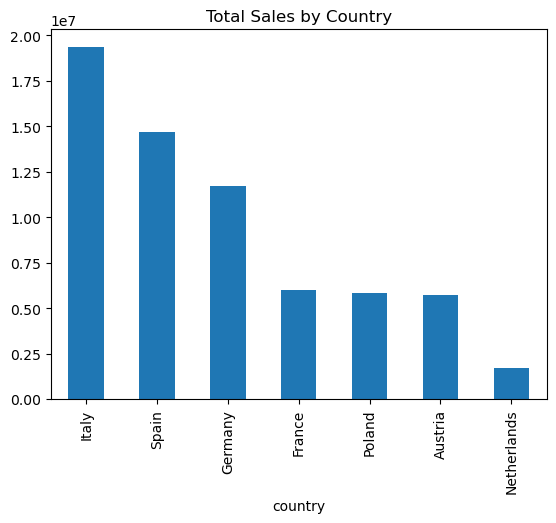

In [26]:
country_sales = df.groupby("country")["units_sold"].sum().sort_values(ascending=False)

country_sales.plot(kind="bar", title="Total Sales by Country")

<Axes: title={'center': 'Top 20 SKUs by Revenue'}, ylabel='sku_id'>

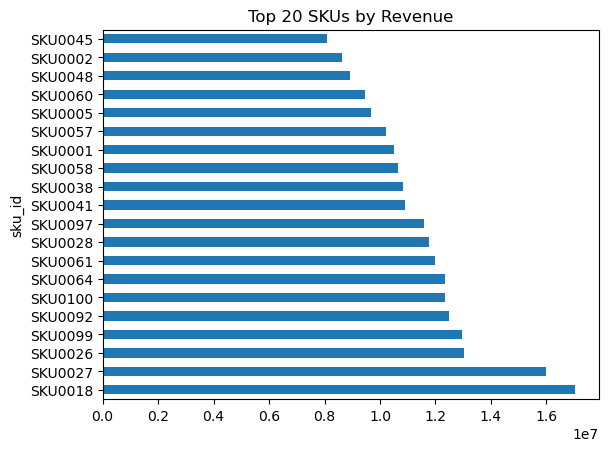

In [15]:
top_skus = df.groupby("sku_id")["net_sales"].sum().sort_values(ascending=False).head(20)

top_skus.plot(kind="barh", title="Top 20 SKUs by Revenue")

In [47]:
sku_sales = df.groupby(["country","sku_id"])["net_sales"].sum().reset_index()

sku_sales = sku_sales.sort_values(["country","net_sales"], ascending=[True, False])

sku_sales["cum_pct"] = sku_sales.groupby("country")["net_sales"].cumsum() / sku_sales.groupby("country")["net_sales"].transform("sum")

def abc(x):
    if x <= 0.7:
        return "A"
    elif x <= 0.9:
        return "B"
    else:
        return "C"

sku_sales["ABC_class"] = sku_sales["cum_pct"].apply(abc)

In [48]:
sku_sales

,country,sku_id,net_sales,cum_pct,ABC_class
20,Austria,SKU0027,1881904.66,0.043745,A
16,Austria,SKU0018,1690621.68,0.083043,A
69,Austria,SKU0092,1582125.30,0.119820,A
42,Austria,SKU0057,1448420.22,0.153488,A
45,Austria,SKU0061,1415742.30,0.186397,A
...,...,...,...,...,...
512,Spain,SKU0029,126754.01,0.996971,C
523,Spain,SKU0040,107463.63,0.997978,C
533,Spain,SKU0051,103232.16,0.998945,C
532,Spain,SKU0050,68680.00,0.999589,C


In [18]:
sku_vol = df.groupby("sku_id")["units_sold"].agg(["mean","std"]).reset_index()
sku_vol["cv"] = sku_vol["std"] / sku_vol["mean"]

def xyz(cv):
    if cv < 0.5:
        return "X"
    elif cv < 1:
        return "Y"
    else:
        return "Z"

sku_vol["XYZ_class"] = sku_vol["cv"].apply(xyz)

In [19]:
sku_vol

,sku_id,mean,std,cv,XYZ_class
0,SKU0001,125.913664,68.857592,0.546864,Y
1,SKU0002,70.020000,31.357488,0.447836,X
2,SKU0003,23.048037,10.478308,0.454629,X
3,SKU0004,100.360548,43.178090,0.430230,X
4,SKU0005,100.136986,54.526935,0.544523,Y
...,...,...,...,...,...
97,SKU0098,47.932918,22.979753,0.479415,X
98,SKU0099,103.145621,54.014256,0.523670,Y
99,SKU0100,84.050594,31.636620,0.376400,X
100,SKU0101,17.144292,8.579464,0.500427,Y


In [20]:
df[["units_sold","list_price","discount_pct","promo_flag"]].corr()

,units_sold,list_price,discount_pct,promo_flag
units_sold,1.000000,-0.082791,0.292777,0.295772
list_price,-0.082791,1.000000,-0.042847,-0.047780
discount_pct,0.292777,-0.042847,1.000000,0.924791
promo_flag,0.295772,-0.047780,0.924791,1.000000


<Axes: >

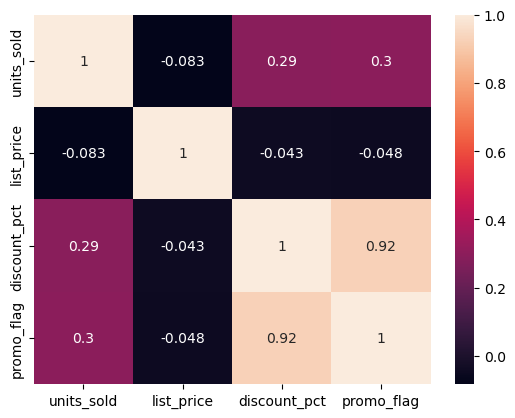

In [21]:
import seaborn as sns
sns.heatmap(df[["units_sold","list_price","discount_pct","promo_flag"]].corr(), annot=True)

<Axes: title={'center': 'Monthly Seasonality'}, xlabel='month'>

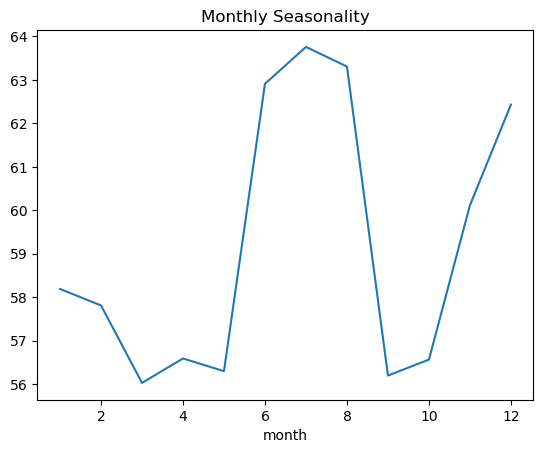

In [22]:
monthly = df.groupby("month")["units_sold"].mean()

monthly.plot(kind="line", title="Monthly Seasonality")

<Axes: title={'center': 'Weekday Sales Pattern'}, xlabel='weekday'>

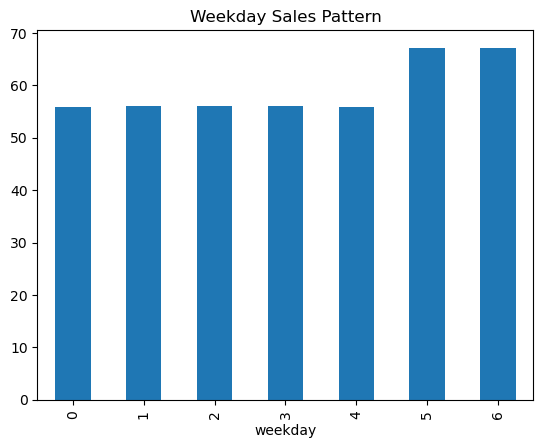

In [23]:
weekly = df.groupby("weekday")["units_sold"].mean()

weekly.plot(kind="bar", title="Weekday Sales Pattern")

In [27]:
selected_skus = df["sku_id"].unique()

In [31]:
selected_skus[:10]

array(['SKU0086', 'SKU0016', 'SKU0049', 'SKU0036', 'SKU0006', 'SKU0067',
       'SKU0063', 'SKU0008', 'SKU0093', 'SKU0018'], dtype=object)

###  ABC -> based on Revenue SKUs selection and based on XYZ on variability

In [49]:
sku_profile = pd.merge(sku_sales, sku_vol, on='sku_id')

In [60]:
selected_skus = []
groups = [
    ('A','X'), ('A','Y'), ('A','Z'),
    ('B','X'), ('B','Y'), ('B','Z'),
    ('C','X'), ('C','Y'), ('C','Z')
]
for a, x in groups:
    subset = sku_profile[(sku_profile['ABC_class']==a) & (sku_profile['XYZ_class']==x)]
    if not subset.empty:
        sku = subset.iloc[0]['sku_id']
        
        if sku not in selected_skus:
            selected_skus.append(sku)
        
# If less than 10,fill randomly
remaining = sku_profile[~sku_profile['sku_id'].isin(selected_skus)]
selected_skus += list(remaining['sku_id'].head(10 - len(selected_skus)))

#The selected_skus are 10 and are of different behaviours based on the XYZ, and ABC classes

In [61]:
selected_skus

['SKU0018',
 'SKU0027',
 'SKU0076',
 'SKU0080',
 'SKU0025',
 'SKU0006',
 'SKU0092',
 'SKU0057',
 'SKU0061',
 'SKU0099']

In [59]:
sku_profile['sku_id'].value_counts().head(10)

sku_id
SKU0027    1
SKU0056    1
SKU0042    1
SKU0003    1
SKU0086    1
SKU0062    1
SKU0008    1
SKU0051    1
SKU0067    1
SKU0085    1
Name: count, dtype: int64

In [58]:
sku_profile = sku_profile.drop_duplicates(subset='sku_id')

## Time to forecast

In [62]:
df = df.sort_values(['sku_id', 'date'])
df.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
54750,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.0,0,505.44,505.44,290,0,7,S050,3.31,0.469
150015,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.0,0,349.44,349.44,107,0,8,S035,3.05,0.511
189435,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.0,0,499.20,499.20,313,0,4,S001,3.49,0.440
343830,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.0,0,624.00,624.00,156,0,7,S046,3.33,0.467
436905,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.0,0,780.00,780.00,390,0,6,S007,4.29,0.312


In [64]:
# Create lag features
for lag in [1, 7, 14]:
    df[f'lag_{lag}'] = df.groupby('sku_id')['units_sold'].shift(lag)
    
df = df.dropna()
df

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct,lag_1,lag_7,lag_14
189437,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,1108.54,265,0,7,S008,3.99,0.211,126.0,118.0,55.0
343832,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,1453.30,412,0,9,S030,4.53,0.125,209.0,192.0,231.0
436907,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,1198.70,385,0,7,S020,3.16,0.344,274.0,182.0,262.0
447857,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,1124.45,305,0,9,S006,3.82,0.237,226.0,146.0,98.0
609917,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,477.36,308,0,7,S021,4.35,0.153,212.0,142.0,318.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
552974,2023-12-31,2023,12,31,52,6,1,0,16.06,5.07,...,466.51,370,0,6,S057,1.67,0.387,172.0,86.0,61.0
626339,2023-12-31,2023,12,31,52,6,1,0,16.06,5.07,...,686.56,280,0,4,S025,2.14,0.245,159.0,116.0,121.0
786209,2023-12-31,2023,12,31,52,6,1,0,16.06,5.07,...,396.09,325,0,10,S017,1.68,0.385,234.0,74.0,163.0
791684,2023-12-31,2023,12,31,52,6,1,0,16.06,5.07,...,812.72,367,0,9,S028,1.69,0.382,135.0,192.0,212.0


In [65]:
# Choose Features

features = [
    'month', 'weekday', 'is_weekend','is_holiday',
    'discount_pct','promo_flag','temperature',
    'lag_1','lag_7','lag_14'
]
target='units_sold'

In [66]:
# Forecast Each SKU

In [67]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

In [68]:
num_df = df.select_dtypes(include=["int64", "float64"])

In [69]:
from pyod.models.iforest import IForest

iforest = IForest().fit(num_df)

probs = iforest.predict_proba(num_df)

is_outlier = probs[:, 1] > 0.75
outliers = num_df[is_outlier]

print(len(outliers))

C:\Users\user\anaconda3\Lib\site-packages\sklearn\base.py:432: UserWarning: X has feature names, but IsolationForest was fitted without feature names
  warnings.warn(


3937


In [70]:
features = [
    "units_sold",
    "net_sales",
    "discount_pct",
    "stock_on_hand",
    "promo_flag"
]

X = df[features]

iforest = IForest(contamination=0.01)
df["anomaly"] = iforest.fit_predict(X)

C:\Users\user\anaconda3\Lib\site-packages\sklearn\utils\deprecation.py:86: FutureWarning: Function fit_predict is deprecated
  warnings.warn(msg, category=FutureWarning)


In [71]:
sku = selected_skus[0]

sku_df = df[df["sku_id"] == sku].copy()
sku_df = sku_df.sort_values("date")

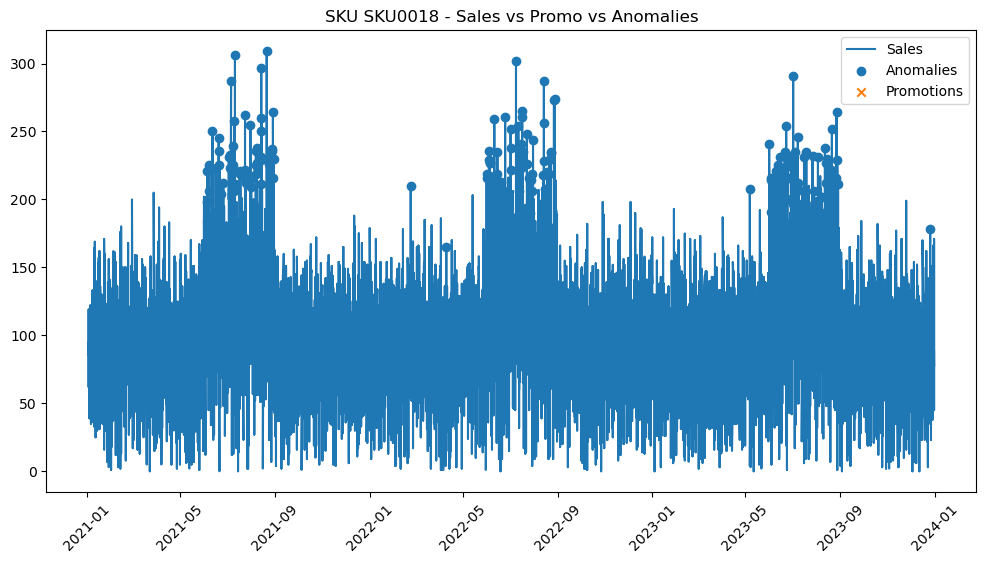

In [84]:
plt.figure(figsize=(12,6))

plt.plot(sku_df["date"], sku_df["units_sold"], label="Sales")

# anomalies
anomalies = sku_df[sku_df["anomaly"] == 1]

plt.scatter(anomalies["date"], anomalies["units_sold"], label="Anomalies")

# promotions overlay
promo_days = sku_df[sku_df["promo_flag"] == 1]

plt.scatter(
    promo_days["date"],
    promo_days["units_sold"],
    label="Promotions",
    marker="x"
)

plt.legend()
plt.title(f"SKU {sku} - Sales vs Promo vs Anomalies")
plt.xticks(rotation=45)

plt.show()

In [89]:
df = df.reset_index()  # moves index to column 'index'
df.rename(columns={"index": "date"}, inplace=True)

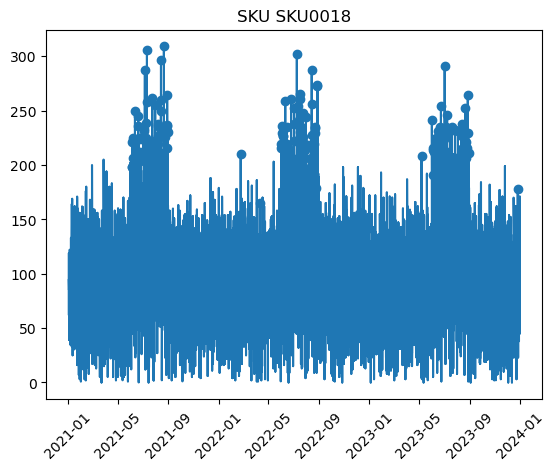

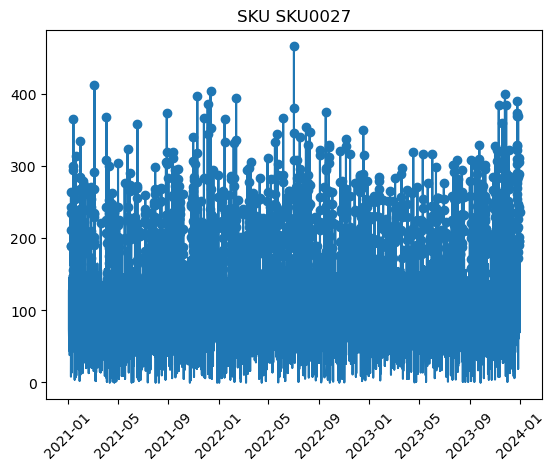

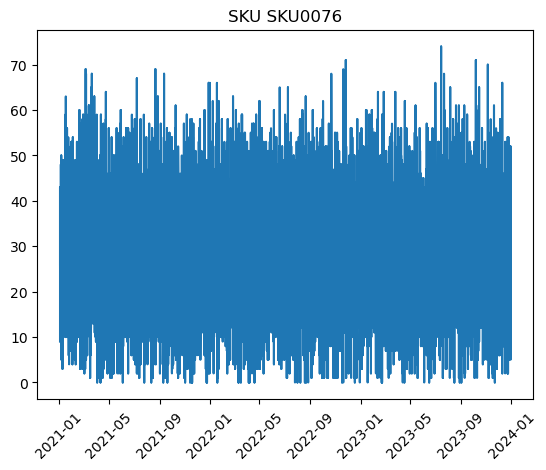

In [90]:
for sku in selected_skus[:3]:
    
    sku_df = df[df["sku_id"] == sku].sort_values("date")
    
    plt.figure()
    plt.plot(sku_df["date"], sku_df["units_sold"])
    
    anomalies = sku_df[sku_df["anomaly"] == 1]
    
    plt.scatter(anomalies["date"], anomalies["units_sold"])
    
    plt.title(f"SKU {sku}")
    plt.xticks(rotation=45)
    
    plt.show()

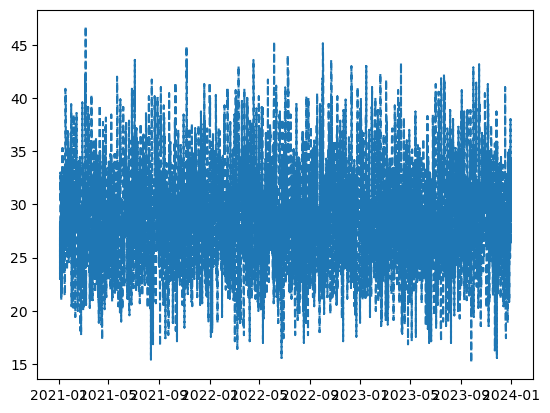

In [91]:
sku_df["rolling_mean"] = sku_df["units_sold"].rolling(7).mean()

plt.plot(sku_df["date"], sku_df["rolling_mean"], linestyle="--", label="Trend")

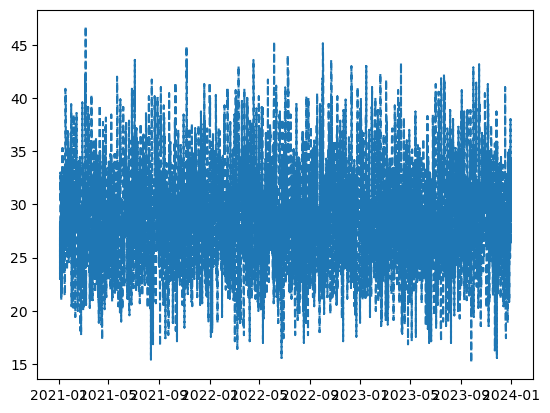

In [92]:
sku_df["rolling_mean"] = sku_df["units_sold"].rolling(7).mean()

plt.plot(sku_df["date"], sku_df["rolling_mean"], linestyle="--", label="Trend")

In [96]:
for lag in [1, 7, 14]:
    df_clean[f"lag_{lag}"] = df_clean.groupby("sku_id")["units_sold"].shift(lag)

df_clean = df_clean.dropna()

In [80]:
sku_df = sku_df.reset_index()  # moves index back to column

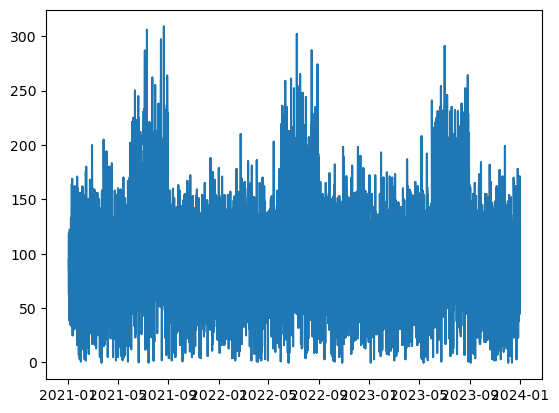

In [83]:
plt.plot(sku_df["date"], sku_df["units_sold"], label="Sales")